## Import packages and load PlantVillage

In [1]:
import tensorflow as tf              # For image processing and deep learning.
import tensorflow_datasets as tfds   # To load the PlantVillage dataset.
import numpy as np                   # Small arrays of labels and dataset indices.
from sklearn.model_selection import train_test_split   # create stratified dataset splits.

In [2]:
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
# Keep iteration order stable so image indices identify the same examples.
# Disable automatic in-memory caching and implicit prefetching.

dataset, info = tfds.load(
    "plant_village", with_info=True, as_supervised=True,
    shuffle_files=False,
    read_config=tfds.ReadConfig(try_autocache=False, skip_prefetch=True),
)
options = tf.data.Options()
options.experimental_deterministic = True
dataset["train"] = dataset["train"].with_options(options)

In [4]:
# Get the complete list of 38 PlantVillage class names.
class_names = info.features["label"].names

# Display the number of images to confirm that loading succeeded.
print("Total PlantVillage images:", info.splits["train"].num_examples)

# Display the number of plant disease and health categories.
print("Total classes:", len(class_names))

Total PlantVillage images: 54303
Total classes: 38


In [5]:
# Display information about the available dataset splits. PlantVillage has one training split
print("Dataset splits:")
print(info.splits)

# Get the number of possible classes from the label feature
print("\nNumber of classes:")
print(info.features["label"].num_classes)

# Get and display the human-readable names associated with each numeric class ID
print("\nClass names:")
print(info.features["label"].names)

Dataset splits:
{'train': <SplitInfo num_examples=54303, num_shards=8>}

Number of classes:
38

Class names:
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomat

## Inspect a few images

In [6]:
# Print the shape and class name for the first five images.
for image, label in tfds.as_numpy(dataset["train"].take(5)):
    # Convert the label to a regular Python integer for list indexing.
    label = int(label)

    # Display the image dimensions, numeric label, readable class name and print an empty line to make the output easier to read
    print("Image shape:", image.shape)
    print("Label:", label)
    print("Class:", class_names[label])
    print()

Image shape: (256, 256, 3)
Label: 35
Class: Tomato___Target_Spot

Image shape: (256, 256, 3)
Label: 15
Class: Orange___Haunglongbing_(Citrus_greening)

Image shape: (256, 256, 3)
Label: 31
Class: Tomato___Late_blight

Image shape: (256, 256, 3)
Label: 20
Class: Potato___Early_blight

Image shape: (256, 256, 3)
Label: 3
Class: Apple___healthy



I0000 00:00:1792031586.912968 2481107 tf_record_dataset_op.cc:396] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


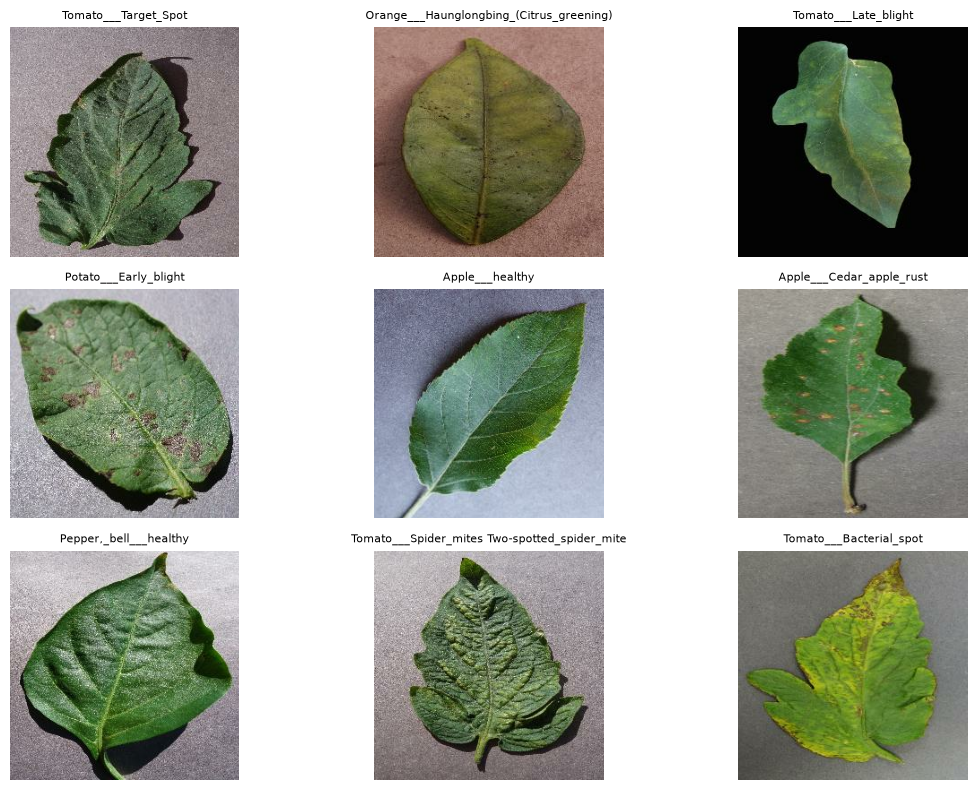

In [7]:
# Import Matplotlib's pyplot module to display images and create plots.
import matplotlib.pyplot as plt

# Create the overall figure/canvas. figsize=(12, 8) means 12 inches wide and 8 inches tall.
plt.figure(figsize=(12, 8))

# Get 9 examples from the training dataset.
# tfds.as_numpy() converts TensorFlow tensors into NumPy arrays.
# enumerate() gives us the position number (i)
# together with the image and its label.
for i, (image, label) in enumerate(
    tfds.as_numpy(dataset["train"].take(9))
):

    # Create a 3 x 3 grid of plots.
    # i + 1 selects the current position in that grid.
    # We use i + 1 because Matplotlib subplot positions
    # start counting from 1 rather than 0.
    plt.subplot(3, 3, i + 1)

    # Display the current leaf image.
    plt.imshow(image)

    # Look up the human-readable class name using the numeric label.
    # For example: label = 35 (Tomato___Target_Spot)
    plt.title(
        info.features["label"].names[label],
        fontsize=8
    )
      # Hide the x-axis and y-axis which coordinate numbers when displaying images.
    plt.axis("off")

# Automatically adjust the spacing between the images and their titles so they don't overlap.
plt.tight_layout()

# Display the completed figure.
plt.show()

In [8]:
# Import Counter, which we can use to count how many times each class label appears
from collections import Counter

# Convert the training dataset into NumPy arrays and extract only the labels
labels = [
    label
    for _, label in tfds.as_numpy(dataset["train"])
]

# Count how many images belong to each numeric class
class_counts = Counter(labels)

# Print the number of images for each class
for class_id, count in sorted(class_counts.items()):

    # Convert the numeric class ID into its human-readable name
    class_name = info.features["label"].names[class_id]

    # Display the class name and number of images
    print(f"{class_id:2d} | {class_name:55s} | {count} images")

 0 | Apple___Apple_scab                                      | 630 images
 1 | Apple___Black_rot                                       | 621 images
 2 | Apple___Cedar_apple_rust                                | 275 images
 3 | Apple___healthy                                         | 1645 images
 4 | Blueberry___healthy                                     | 1502 images
 5 | Cherry___healthy                                        | 854 images
 6 | Cherry___Powdery_mildew                                 | 1052 images
 7 | Corn___Cercospora_leaf_spot Gray_leaf_spot              | 513 images
 8 | Corn___Common_rust                                      | 1192 images
 9 | Corn___healthy                                          | 1162 images
10 | Corn___Northern_Leaf_Blight                             | 985 images
11 | Grape___Black_rot                                       | 1180 images
12 | Grape___Esca_(Black_Measles)                            | 1383 images
13 | Grape___healthy           

In [9]:
# Get the list of all class names from the PlantVillage dataset
class_names = info.features["label"].names

# Find all class IDs whose class name starts with "Tomato___"
# enumerate() gives us both the numeric ID and the class name.
tomato_class_ids = [
    class_id
    for class_id, class_name in enumerate(class_names)
    if class_name.startswith("Tomato___")
]

# Display the numeric IDs of all Tomato classes
print("Tomato class IDs:")
print(tomato_class_ids)

# Display the corresponding Tomato class names
print("\nTomato class names:")

# Loop through each Tomato class ID
for class_id in tomato_class_ids:

    # Get the class name associated with the current ID
    class_name = class_names[class_id]

    # Display the ID and its class name
    print(f"{class_id}: {class_name}")

Tomato class IDs:
[28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

Tomato class names:
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___healthy
31: Tomato___Late_blight
32: Tomato___Leaf_Mold
33: Tomato___Septoria_leaf_spot
34: Tomato___Spider_mites Two-spotted_spider_mite
35: Tomato___Target_Spot
36: Tomato___Tomato_mosaic_virus
37: Tomato___Tomato_Yellow_Leaf_Curl_Virus


## Identify the 10 tomato classes

In [10]:
# Store the Tomato class IDs in a set.
tomato_class_id_set = set(tomato_class_ids)

# Define a function that receives one image and its label.
def is_tomato(image, label):
    
    return tf.reduce_any(
        tf.equal(label, tomato_class_ids)
    )
    
# Filter the complete PlantVillage training dataset.
tomato_dataset = dataset["train"].filter(is_tomato)

# Print a confirmation message so we know that the filtering operation was created successfully.
print("Tomato dataset created successfully!")

Tomato dataset created successfully!


In [11]:
# Count how many examples are present in our Tomato-only dataset.
tomato_count = sum(
    1
    for _ in tomato_dataset
)

# Display the total number of Tomato images.
print("Total Tomato images:", tomato_count)

Total Tomato images: 18159


In [12]:
# Create a dictionary that maps each original PlantVillage Tomato class ID to a new class ID from 0 to 9.
tomato_label_map = {
    old_label: new_label
    for new_label, old_label in enumerate(tomato_class_ids)
}

print("Tomato label mapping:")

# Loop through each original and new label pair.
for old_label, new_label in tomato_label_map.items():
    class_name = class_names[old_label]
    print(
        f"{old_label} → {new_label} | {class_name}"
    )

Tomato label mapping:
28 → 0 | Tomato___Bacterial_spot
29 → 1 | Tomato___Early_blight
30 → 2 | Tomato___healthy
31 → 3 | Tomato___Late_blight
32 → 4 | Tomato___Leaf_Mold
33 → 5 | Tomato___Septoria_leaf_spot
34 → 6 | Tomato___Spider_mites Two-spotted_spider_mite
35 → 7 | Tomato___Target_Spot
36 → 8 | Tomato___Tomato_mosaic_virus
37 → 9 | Tomato___Tomato_Yellow_Leaf_Curl_Virus


## Filter tomato images and remap labels to 0–9

In [13]:
# Define a function that will be applied to every image and label in our Tomato dataset.
def remap_label(image, old_label):

    # Create a TensorFlow constant containing our original Tomato class IDs: 28, 29, ..., 37.
    tomato_ids = tf.constant(tomato_class_ids, dtype=tf.int64)

    # Find where the original label appears in tomato_ids.
    new_label = tf.argmax(
        tf.cast(tf.equal(tomato_ids, old_label), tf.int64)
    )

    # Return the original image unchanged, together with its new label.
    return image, new_label

# Apply the remapping function to every example in Tomato-only dataset.
tomato_dataset_remapped = tomato_dataset.map(
    remap_label
)

# Print a confirmation message.
print("Tomato labels successfully remapped!")

Tomato labels successfully remapped!


In [14]:
# Take the first 10 examples from our remapped Tomato dataset.

for image, label in tfds.as_numpy(
    tomato_dataset_remapped.take(10)
):
    # Convert the TensorFlow/NumPy label into a normal Python integer.
    label = int(label)

    # Get the original Tomato class name using the new label as the position in tomato_class_ids.
    original_class_id = tomato_class_ids[label]

    # Get the human-readable class name.
    class_name = class_names[original_class_id]

    # Display the new numeric label and its class name.
    print(
        f"New label: {label} | Class: {class_name}"
    )

New label: 7 | Class: Tomato___Target_Spot
New label: 3 | Class: Tomato___Late_blight
New label: 6 | Class: Tomato___Spider_mites Two-spotted_spider_mite
New label: 0 | Class: Tomato___Bacterial_spot
New label: 3 | Class: Tomato___Late_blight
New label: 2 | Class: Tomato___healthy
New label: 6 | Class: Tomato___Spider_mites Two-spotted_spider_mite
New label: 8 | Class: Tomato___Tomato_mosaic_virus
New label: 9 | Class: Tomato___Tomato_Yellow_Leaf_Curl_Virus
New label: 9 | Class: Tomato___Tomato_Yellow_Leaf_Curl_Virus


In [15]:
# Create an empty dictionary to store the number of images belonging to each of 10 Tomato classes.
tomato_remapped_counts = {}

# Loop through every image and its remapped label in the Tomato dataset.
for _, label in tfds.as_numpy(tomato_dataset_remapped):

    # Convert the label into a normal Python integer.
    label = int(label)

    # If this label has not been seen before, start its count at zero.
    if label not in tomato_remapped_counts:
        tomato_remapped_counts[label] = 0

    # Increase the count for this class by one.
    tomato_remapped_counts[label] += 1

# Print the class distribution.
print("Tomato class distribution after remapping:")
print()

# Loop through labels 0 through 9 in order.
for label in range(10):

    # Get the original PlantVillage class ID corresponding to new label.
    original_class_id = tomato_class_ids[label]

    # Get the human-readable class name.
    class_name = class_names[original_class_id]

    # Get the number of images for this class.
    count = tomato_remapped_counts[label]

    # Print the label, class name, and image count.
    print(
        f"{label} | {class_name} | {count} images"
    )

Tomato class distribution after remapping:

0 | Tomato___Bacterial_spot | 2127 images
1 | Tomato___Early_blight | 1000 images
2 | Tomato___healthy | 1591 images
3 | Tomato___Late_blight | 1908 images
4 | Tomato___Leaf_Mold | 952 images
5 | Tomato___Septoria_leaf_spot | 1771 images
6 | Tomato___Spider_mites Two-spotted_spider_mite | 1676 images
7 | Tomato___Target_Spot | 1404 images
8 | Tomato___Tomato_mosaic_virus | 373 images
9 | Tomato___Tomato_Yellow_Leaf_Curl_Virus | 5357 images


## Verify tomato class counts

In [16]:
# Store only labels and indices. Images stay in the disk-backed dataset.
tomato_labels = np.fromiter(
    (int(label) for _, label in tfds.as_numpy(tomato_dataset_remapped)),
    dtype=np.int64,
)
tomato_indices = np.arange(len(tomato_labels), dtype=np.int64)
assert len(tomato_labels) == tomato_count
print("Total images:", len(tomato_labels))
print("Label/index memory (MiB):", (tomato_labels.nbytes + tomato_indices.nbytes) / 1024**2)

Total images: 18159
Label/index memory (MiB): 0.2770843505859375


## Create the Train - Validation - Test split

In [17]:
# Preserve the stratified 70% / 15% / 15% split without copying images.

train_indices, temp_indices, y_train, y_temp = train_test_split(
    tomato_indices, tomato_labels, test_size=0.30,
    random_state=42, stratify=tomato_labels,
)

In [18]:
val_indices, test_indices, y_val, y_test = train_test_split(
    temp_indices, y_temp, test_size=0.50,
    random_state=42, stratify=y_temp,
)
# Confirm every example belongs to exactly one split.
all_indices = np.concatenate([train_indices, val_indices, test_indices])
assert len(np.unique(all_indices)) == len(tomato_labels)
assert np.array_equal(np.sort(all_indices), tomato_indices)

In [19]:
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Test images:", len(test_indices))
print("Total images:", len(tomato_labels))

Training images: 12711
Validation images: 2724
Test images: 2724
Total images: 18159


In [20]:
# Import Counter so that we can count how many images belong to each class.
from collections import Counter

# Count the number of images belonging to each class in the training dataset.
train_counts = Counter(y_train)

# Count the number of images belonging to each class in the validation dataset.
val_counts = Counter(y_val)

# Count the number of images belonging to each class in the test dataset.
test_counts = Counter(y_test)

print("Class distribution across Train / Validation / Test:")
print()
# Loop through all 10 Tomato classes.
for label in range(10):

    # Get the original PlantVillage class ID associated with our new label.
    original_class_id = tomato_class_ids[label]

    # Get the human-readable class name.
    class_name = class_names[original_class_id]

    # Get the number of training images for this class.
    train_count = train_counts[label]

    # Get the number of validation images for this class.
    val_count = val_counts[label]

    # Get the number of test images for this class.
    test_count = test_counts[label]

    # Display the distribution for this class.
    print(
        f"{label} | "
        f"{class_name:50s} | "
        f"Train: {train_count:4d} | "
        f"Validation: {val_count:4d} | "
        f"Test: {test_count:4d}"
    )

Class distribution across Train / Validation / Test:

0 | Tomato___Bacterial_spot                            | Train: 1489 | Validation:  319 | Test:  319
1 | Tomato___Early_blight                              | Train:  700 | Validation:  150 | Test:  150
2 | Tomato___healthy                                   | Train: 1114 | Validation:  239 | Test:  238
3 | Tomato___Late_blight                               | Train: 1335 | Validation:  287 | Test:  286
4 | Tomato___Leaf_Mold                                 | Train:  666 | Validation:  143 | Test:  143
5 | Tomato___Septoria_leaf_spot                        | Train: 1240 | Validation:  265 | Test:  266
6 | Tomato___Spider_mites Two-spotted_spider_mite      | Train: 1173 | Validation:  251 | Test:  252
7 | Tomato___Target_Spot                               | Train:  983 | Validation:  210 | Test:  211
8 | Tomato___Tomato_mosaic_virus                       | Train:  261 | Validation:   56 | Test:   56
9 | Tomato___Tomato_Yellow_Leaf_Curl_

## Preprocess images in small batches

In [21]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

def preprocess(image, label):
    # Convert only the current image, rather than the entire dataset.
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def make_split(indices, training=False):
    membership = np.zeros(len(tomato_labels), dtype=bool)
    membership[indices] = True
    membership = tf.constant(membership)
    split = tomato_dataset_remapped.enumerate().filter(
        lambda index, example: tf.gather(membership, index)
    )
    split = split.map(lambda index, example: example, num_parallel_calls=1)
    split = split.apply(tf.data.experimental.assert_cardinality(len(indices)))
    if training:
        # Bounded shuffle buffer; do not cache the whole image dataset.
        split = split.shuffle(128, seed=SEED, reshuffle_each_iteration=True)
    split = split.map(preprocess, num_parallel_calls=1)
    return split.batch(BATCH_SIZE).prefetch(1)

train_ds = make_split(train_indices, training=True)
val_ds = make_split(val_indices)
test_ds = make_split(test_indices)
print("Datasets ready. Batch size:", BATCH_SIZE)

Datasets ready. Batch size: 16


In [22]:
# Verify preprocessing before starting training.
for images, batch_labels in train_ds.take(1):
    tf.debugging.assert_all_finite(images, "Invalid image values")
    tf.debugging.assert_greater_equal(images, 0.0)
    tf.debugging.assert_less_equal(images, 1.0)
    tf.debugging.assert_greater_equal(batch_labels, tf.cast(0, batch_labels.dtype))
    tf.debugging.assert_less(batch_labels, tf.cast(len(tomato_class_ids), batch_labels.dtype))
    print("Image batch:", images.shape, images.dtype)
    print("Label batch:", batch_labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))
    print("Image batch memory (MiB):", images.numpy().nbytes / 1024**2)

Image batch: (16, 128, 128, 3) <dtype: 'float32'>
Label batch: (16,)
Pixel range: 0.0 0.9607843160629272
Image batch memory (MiB): 3.0


## Build and Train the Baseline CNN

In [23]:
# Next step: train a small CNN baseline.
from pathlib import Path

tf.keras.utils.set_random_seed(SEED)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(*IMAGE_SIZE, 3)),
    tf.keras.layers.Conv2D(16, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu", padding="same"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu", padding="same"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(tomato_class_ids), activation="softmax"),
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# Save the best validation model so training progress survives a later restart.
artifact_dir = Path("plant_health_results")
artifact_dir.mkdir(exist_ok=True)
history = model.fit(
    train_ds, validation_data=val_ds, epochs=5,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(artifact_dir / "best_tomato_baseline.keras"),
            monitor="val_loss", save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,394 (110.91 KB)

 Trainable params: 28,394 (110.91 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


/opt/anaconda3/envs/PlantHealth_DL/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


795/795 ━━━━━━━━━━━━━━━━━━━━ 83s 103ms/step - accuracy: 0.4126 - loss: 1.7069 - val_accuracy: 0.5202 - val_loss: 1.3955
Epoch 2/5
795/795 ━━━━━━━━━━━━━━━━━━━━ 93s 117ms/step - accuracy: 0.5517 - loss: 1.2963 - val_accuracy: 0.6516 - val_loss: 0.9847
Epoch 3/5
795/795 ━━━━━━━━━━━━━━━━━━━━ 86s 108ms/step - accuracy: 0.6413 - loss: 1.0275 - val_accuracy: 0.7265 - val_loss: 0.7958
Epoch 4/5
795/795 ━━━━━━━━━━━━━━━━━━━━ 84s 105ms/step - accuracy: 0.6881 - loss: 0.8828 - val_accuracy: 0.7566 - val_loss: 0.6772
Epoch 5/5
795/795 ━━━━━━━━━━━━━━━━━━━━ 86s 108ms/step - accuracy: 0.7315 - loss: 0.7686 - val_accuracy: 0.7882 - val_loss: 0.6078


## Evaluate and Save the Baseline Model

Use validation results to choose model improvements. Reserve the test split for
final evaluation rather than repeatedly tuning against it. PlantVillage results
measure performance on this dataset; field photos require separate validation.

In [24]:
# Evaluate the best checkpoint after completing the baseline experiment.
best_model = tf.keras.models.load_model(artifact_dir / "best_tomato_baseline.keras")
test_metrics = best_model.evaluate(test_ds, return_dict=True)
print("Test metrics:", test_metrics)

import json
mapping = {i: class_names[old_id] for i, old_id in enumerate(tomato_class_ids)}
(artifact_dir / "class_names.json").write_text(json.dumps(mapping, indent=2))
np.savez(artifact_dir / "split_indices.npz", train=train_indices,
         validation=val_indices, test=test_indices)
print("Saved model, class names, and split indices in:", artifact_dir.resolve())

171/171 ━━━━━━━━━━━━━━━━━━━━ 14s 78ms/step - accuracy: 0.7757 - loss: 0.6265
Test metrics: {'accuracy': 0.7756975293159485, 'loss': 0.6265057921409607}
Saved model, class names, and split indices in: /Users/archana/Desktop/AI-Course/DL_Smart_Plant_Health_Detection/notebooks/plant_health_results


In [25]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,184 (332.75 KB)

 Trainable params: 28,394 (110.91 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 56,790 (221.84 KB)

## Review the Model Architecture and Training Curves

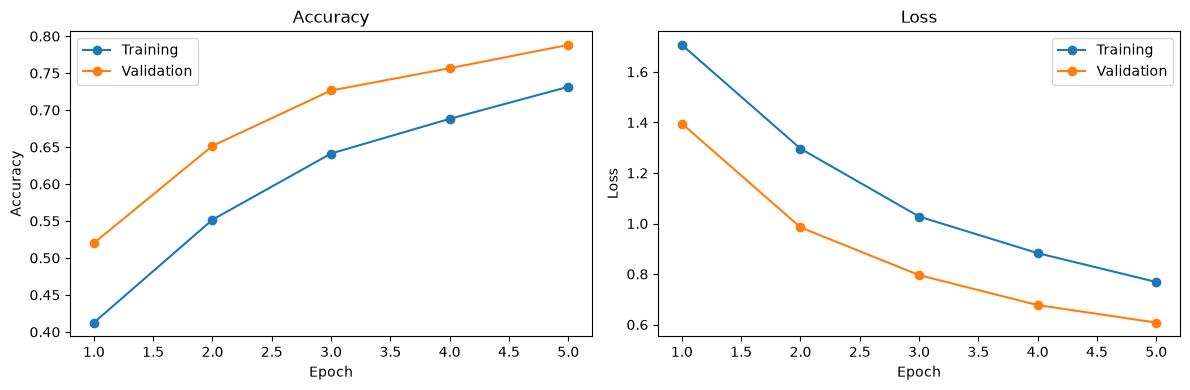

In [26]:
import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history["accuracy"], "o-", label="Training")
axes[0].plot(epochs, history.history["val_accuracy"], "o-", label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs, history.history["loss"], "o-", label="Training")
axes[1].plot(epochs, history.history["val_loss"], "o-", label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [27]:
import numpy as np
from sklearn.metrics import classification_report

true_labels = []
predicted_labels = []

# Collect predictions and their matching labels in the same loop.
for images, labels in val_ds:
    probabilities = best_model(images, training=False).numpy()
    true_labels.extend(labels.numpy())
    predicted_labels.extend(np.argmax(probabilities, axis=1))

tomato_names = [
    class_names[class_id].replace("Tomato___", "")
    for class_id in tomato_class_ids
]

print(classification_report(
    true_labels,
    predicted_labels,
    labels=list(range(len(tomato_names))),
    target_names=tomato_names,
    digits=3,
    zero_division=0
))

                                      precision    recall  f1-score   support

                      Bacterial_spot      0.905     0.868     0.886       319
                        Early_blight      0.662     0.313     0.425       150
                             healthy      0.803     0.975     0.881       239
                         Late_blight      0.629     0.603     0.616       287
                           Leaf_Mold      0.825     0.329     0.470       143
                  Septoria_leaf_spot      0.676     0.857     0.755       265
Spider_mites Two-spotted_spider_mite      0.667     0.829     0.739       251
                         Target_Spot      0.594     0.676     0.633       210
                 Tomato_mosaic_virus      1.000     0.464     0.634        56
       Tomato_Yellow_Leaf_Curl_Virus      0.945     0.954     0.949       804

                            accuracy                          0.788      2724
                           macro avg      0.771     0.687     

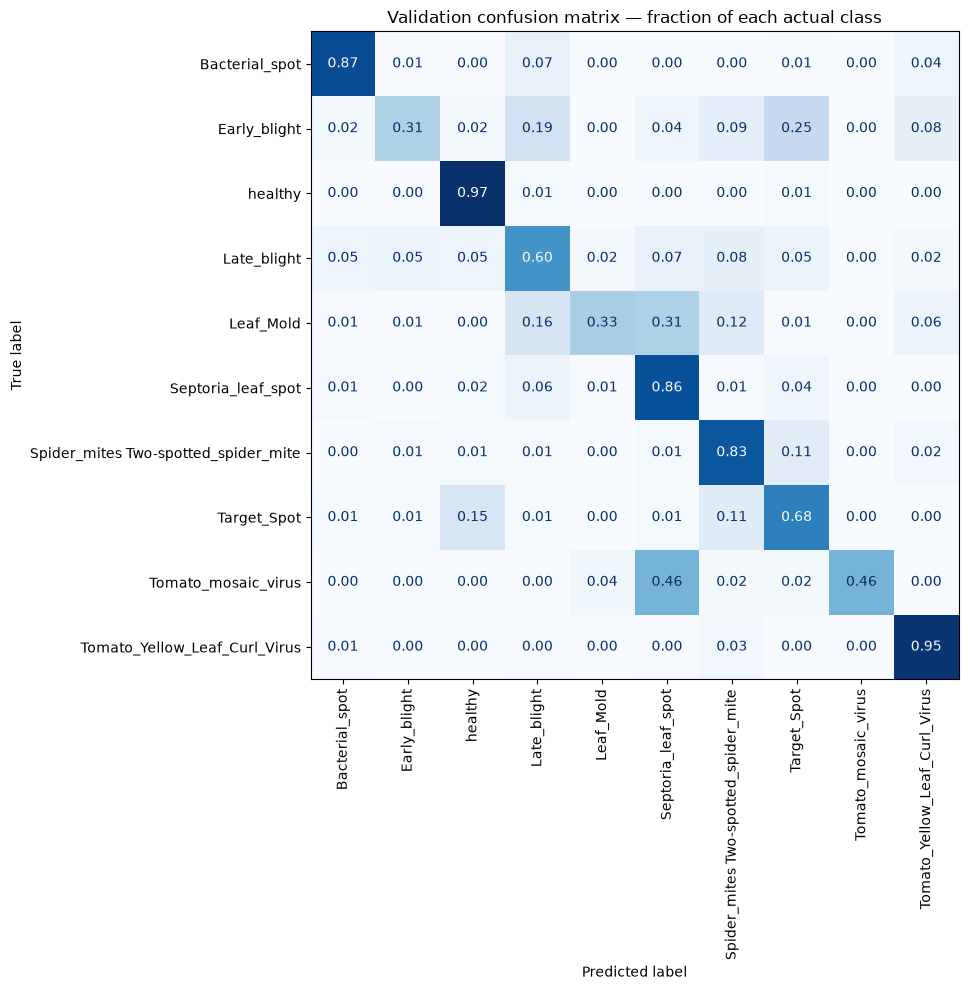

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=list(range(len(tomato_names))),
    normalize="true"
)

fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=tomato_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title("Validation confusion matrix — fraction of each actual class")
plt.tight_layout()
plt.show()


In [29]:
from pathlib import Path

artifact_dir = Path("plant_health_results")
artifact_dir.mkdir(exist_ok=True)

baseline_model = best_model
baseline_model.save(artifact_dir / "baseline_5epochs.keras")

baseline_val_accuracy = float(
    np.mean(np.array(true_labels) == np.array(predicted_labels))
)

print(f"Baseline validation accuracy: {baseline_val_accuracy:.2%}")
print("Baseline saved:", artifact_dir / "baseline_5epochs.keras")


Baseline validation accuracy: 78.82%
Baseline saved: plant_health_results/baseline_5epochs.keras


In [30]:
# Load a separate copy so the baseline remains available.
continued_model = tf.keras.models.load_model(
    artifact_dir / "baseline_5epochs.keras"
)

continued_history = continued_model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=5,
    epochs=10,  # Runs epochs 6–10, not ten additional epochs.
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            str(artifact_dir / "continued_best.keras"),
            monitor="val_loss",
            save_best_only=True,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
    ],
)

Epoch 6/10


/opt/anaconda3/envs/PlantHealth_DL/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


795/795 ━━━━━━━━━━━━━━━━━━━━ 84s 105ms/step - accuracy: 0.7582 - loss: 0.6919 - val_accuracy: 0.7779 - val_loss: 0.6201
Epoch 7/10
795/795 ━━━━━━━━━━━━━━━━━━━━ 85s 107ms/step - accuracy: 0.7772 - loss: 0.6476 - val_accuracy: 0.8183 - val_loss: 0.4983
Epoch 8/10
795/795 ━━━━━━━━━━━━━━━━━━━━ 81s 102ms/step - accuracy: 0.7887 - loss: 0.6165 - val_accuracy: 0.7992 - val_loss: 0.5710
Epoch 9/10
795/795 ━━━━━━━━━━━━━━━━━━━━ 77s 97ms/step - accuracy: 0.8008 - loss: 0.5872 - val_accuracy: 0.8421 - val_loss: 0.4324
Epoch 10/10
795/795 ━━━━━━━━━━━━━━━━━━━━ 77s 96ms/step - accuracy: 0.8060 - loss: 0.5553 - val_accuracy: 0.8135 - val_loss: 0.5030


In [32]:
improved_model = tf.keras.models.load_model(
    artifact_dir / "continued_best.keras"
)

validation_results = improved_model.evaluate(
    val_ds, return_dict=True
)

print(
    f"Validation accuracy: "
    f"{validation_results['accuracy']:.2%}"
)
print(
    f"Validation loss: "
    f"{validation_results['loss']:.4f}"
)

171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8421 - loss: 0.4324
Validation accuracy: 84.21%
Validation loss: 0.4324


In [33]:
improved_true = []
improved_predictions = []

for images, labels in val_ds:
    probabilities = improved_model(images, training=False).numpy()
    improved_true.extend(labels.numpy())
    improved_predictions.extend(np.argmax(probabilities, axis=1))

print(classification_report(
    improved_true,
    improved_predictions,
    labels=list(range(len(tomato_names))),
    target_names=tomato_names,
    digits=3,
    zero_division=0
))

                                      precision    recall  f1-score   support

                      Bacterial_spot      0.960     0.821     0.885       319
                        Early_blight      0.661     0.520     0.582       150
                             healthy      0.901     0.992     0.944       239
                         Late_blight      0.721     0.666     0.692       287
                           Leaf_Mold      0.856     0.622     0.721       143
                  Septoria_leaf_spot      0.768     0.913     0.834       265
Spider_mites Two-spotted_spider_mite      0.734     0.793     0.762       251
                         Target_Spot      0.788     0.743     0.765       210
                 Tomato_mosaic_virus      0.938     0.804     0.865        56
       Tomato_Yellow_Leaf_Curl_Virus      0.915     0.989     0.950       804

                            accuracy                          0.842      2724
                           macro avg      0.824     0.786     

## Display Predictions on Validation Images

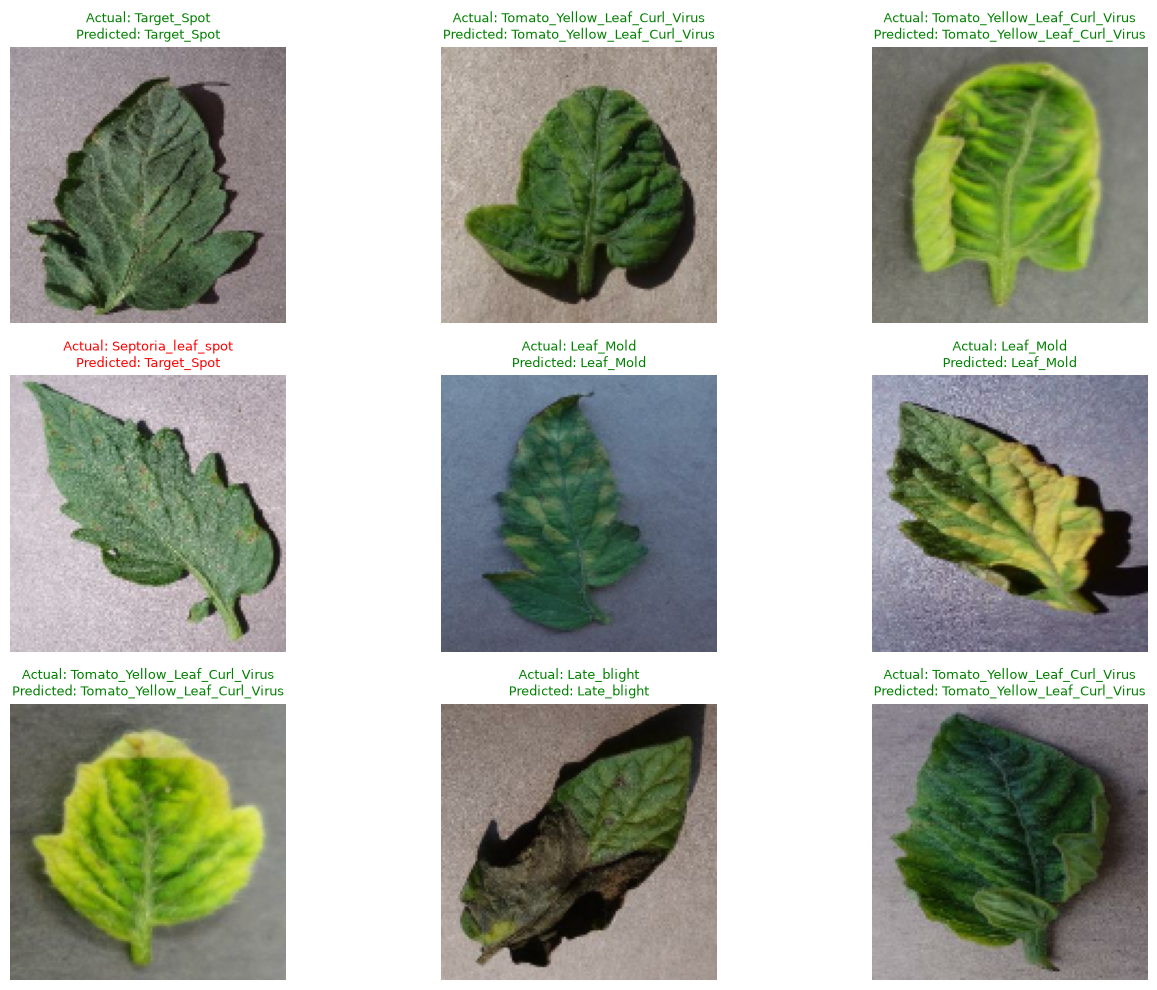

In [34]:
images, labels = next(iter(val_ds))
probabilities = improved_model(images, training=False).numpy()
predictions = np.argmax(probabilities, axis=1)

plt.figure(figsize=(14, 10))

for i in range(min(9, len(images))):
    actual = int(labels[i])
    predicted = int(predictions[i])

    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(
        f"Actual: {tomato_names[actual]}\n"
        f"Predicted: {tomato_names[predicted]}",
        color="green" if actual == predicted else "red",
        fontsize=9,
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
import json

model_path = artifact_dir / "tomato_cnn_selected.keras"
improved_model.save(model_path)

class_mapping = {
    str(i): class_names[class_id]
    for i, class_id in enumerate(tomato_class_ids)
}

mapping_path = artifact_dir / "class_names.json"
mapping_path.write_text(json.dumps(class_mapping, indent=2))

print("Model saved:", model_path.resolve())
print("Class mapping saved:", mapping_path.resolve())

Model saved: /Users/archana/Desktop/AI-Course/DL_Smart_Plant_Health_Detection/notebooks/plant_health_results/tomato_cnn_selected.keras
Class mapping saved: /Users/archana/Desktop/AI-Course/DL_Smart_Plant_Health_Detection/notebooks/plant_health_results/class_names.json


## Save a Sample Tomato Leaf Image

In [39]:
# Take one image from the validation dataset.
sample_images, sample_labels = next(iter(val_ds))

# Convert normalized pixels back to the 0–255 range.
image_pixels = (
    sample_images[0].numpy() * 255
).round().clip(0, 255).astype("uint8")

# Save the image in your results folder.
image_path = artifact_dir / "sample_tomato_leaf.jpg"
tf.keras.utils.save_img(
    str(image_path), image_pixels, scale=False
)

print("Image saved:", image_path.resolve())
print("Image found:", image_path.is_file())
print("Actual class:", tomato_names[int(sample_labels[0])])

Image saved: /Users/archana/Desktop/AI-Course/DL_Smart_Plant_Health_Detection/notebooks/plant_health_results/sample_tomato_leaf.jpg
Image found: True
Actual class: Target_Spot


## Load the Saved Model and Predict a Leaf Image

Predicted class: Target_Spot
Model score: 86.3%


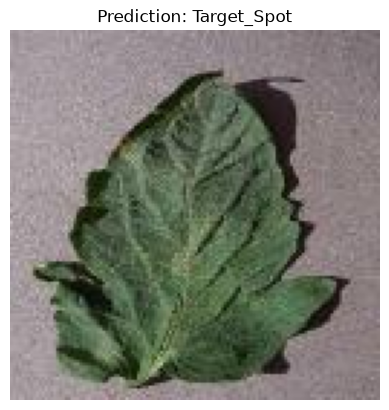

In [40]:
# Load the image and apply the same preprocessing used in training.
loaded_image = tf.keras.utils.load_img(
    str(image_path), target_size=IMAGE_SIZE
)
image_array = tf.keras.utils.img_to_array(loaded_image) / 255.0
image_batch = np.expand_dims(image_array, axis=0)

# Predict using the saved model.
saved_model = tf.keras.models.load_model(
    artifact_dir / "tomato_cnn_selected.keras"
)
scores = saved_model(image_batch, training=False).numpy()[0]
predicted_id = int(np.argmax(scores))

print("Predicted class:", tomato_names[predicted_id])
print(f"Model score: {scores[predicted_id]:.1%}")

plt.imshow(loaded_image)
plt.title(f"Prediction: {tomato_names[predicted_id]}")
plt.axis("off")
plt.show()

## Evaluate the Selected Model on the Test Set

In [41]:
final_test_results = saved_model.evaluate(
    test_ds, return_dict=True
)

print(f"Selected model test accuracy: {final_test_results['accuracy']:.2%}")
print(f"Selected model test loss: {final_test_results['loss']:.4f}")

171/171 ━━━━━━━━━━━━━━━━━━━━ 13s 77ms/step - accuracy: 0.8447 - loss: 0.4521
Selected model test accuracy: 84.47%
Selected model test loss: 0.4521


## Save the Final Evaluation Results

In [42]:
import json

results = {
    "selected_epoch": 9,
    "baseline_test_accuracy": 0.7756975293159485,
    "selected_validation_accuracy": float(
        validation_results["accuracy"]
    ),
    "selected_test_accuracy": float(
        final_test_results["accuracy"]
    ),
    "selected_test_loss": float(
        final_test_results["loss"]
    ),
    "validation_macro_f1_rounded": 0.800,
}

results_path = artifact_dir / "evaluation_results.json"
results_path.write_text(json.dumps(results, indent=2))

print("Results saved:", results_path.resolve())

Results saved: /Users/archana/Desktop/AI-Course/DL_Smart_Plant_Health_Detection/notebooks/plant_health_results/evaluation_results.json


## Create a Reusable Leaf Image Prediction Function

Predicted class: Tomato___Target_Spot
Model score: 86.3%


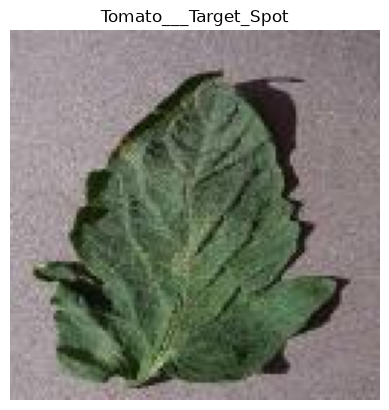

In [48]:
# Read the class mapping saved alongside the model.
with open(artifact_dir / "class_names.json") as file:
    saved_class_names = json.load(file)

def predict_leaf(image_file):
    image_file = Path(image_file)

    if not image_file.is_file():
        raise FileNotFoundError(f"Image not found: {image_file}")

    image = tf.keras.utils.load_img(
        str(image_file), target_size=IMAGE_SIZE
    )
    image_array = tf.keras.utils.img_to_array(image) / 255.0
    batch = np.expand_dims(image_array, axis=0)

    scores = saved_model(batch, training=False).numpy()[0]
    predicted_id = int(np.argmax(scores))
    predicted_class = saved_class_names[str(predicted_id)]
    score = float(scores[predicted_id])

    print("Predicted class:", predicted_class)
    print(f"Model score: {score:.1%}")

    plt.imshow(image)
    plt.title(predicted_class)
    plt.axis("off")
    plt.show()

    return predicted_class, score

# Check the function using your saved sample image.
prediction, score = predict_leaf(image_path)